# Solar radiation splitting

Reproduce Figure 8: observed shortwave radiation closure and the Perez (1992)
and Reindl (1990) estimates of direct normal (DNI) and diffuse horizontal (DHI)
irradiance at ENGI, FRIE, GROP and MAVI. The final section adds the Bristol
ERA5 component and diffuse-fraction comparisons in Figures S6.1 and S6.2.
All evaluations use hourly means.

Inputs are the embargoed calibrated, flagged one-minute radiation CSVs and
prepared, timestamp-aligned meteorological CSVs, supplied separately with
authorised access. ERA5 radiation for the supplementary section is included in
`ERA5_radiation/`. Configure the observation paths and run the cells in order. Figures are
saved at 400 dpi in `figures/`; statistics and evaluation periods are displayed
alongside the calculations. No source observations are modified or copied.

## Setup

Radiation and aligned meteorological observations are embargoed and are not
included in this repository or the Zenodo modelling-results deposit.
Replace the placeholder directories below only when authorised inputs are available:
`RADIATION_DIR` contains the four `<site>_All_Radiation_data_flagged.csv` files;
`METEOROLOGY_DIR` contains the four `<site>_Meteorology_aligned.csv` files.
Site codes are ENGI, FRIE, GROP and MAVI. Keep these inputs outside the public
repository. Running this notebook requires access to both datasets.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib
from IPython.display import display

RADIATION_DIR = Path('path/to/authorised_solar_radiation')
METEOROLOGY_DIR = Path('path/to/authorised_solar_meteorology')
FIGURE_DIR = Path('figures')
FIGURE_DIR.mkdir(exist_ok=True)

# Latitude (degrees N), longitude (degrees E), instrument altitude (m ASL).
SITES = {
    'ENGI': dict(city='Bristol', latitude=51.456611, longitude=-2.601, altitude=62.91),
    'FRIE': dict(city='Berlin', latitude=52.507556, longitude=13.397881, altitude=107.8),
    'GROP': dict(city='Berlin', latitude=52.422949, longitude=13.473843, altitude=123.9),
    'MAVI': dict(city='Berlin', latitude=52.592138, longitude=13.355699, altitude=71.1),
}
for site, config in SITES.items():
    config['file'] = RADIATION_DIR / f'{site}_All_Radiation_data_flagged.csv'
    config['met_file'] = METEOROLOGY_DIR / f'{site}_Meteorology_aligned.csv'

RESOLUTION = '1h'
MIN_COVERAGE = 1.0  # All 60 minutes are required; no interpolation.
ACCEPTED_FLAGS = (0,)
GHI_MIN, ZENITH_MAX = 20.0, 85.0
USE_STABILITY_CORRECTION = True  # DIRINT temporal-variability correction.

COLOURS = {'Perez': '#0072B2', 'Reindl': '#D55E00'}
MARKERS = {'Perez': 'o', 'Reindl': 'x'}
PANEL_METRICS = ('N', 'MAE', 'MBE', 'RMSE', 'R2', 'slope0')
FIGSIZE = (12, 13.6)
ROW_SPACING = 0.17
FIGURE_DPI = 400
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.labelsize': 10, 'axes.titlesize': 11, 'axes.titleweight': 'normal',
    'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.18, 'axes.axisbelow': True,
    'figure.dpi': 400, 'savefig.dpi': FIGURE_DPI,
})

## Prepare observations

Radiation requires finite, nonnegative values with flag 0. Meteorology uses air
temperature, relative humidity, logger-reported dew point and station pressure
(Pa), with the basic validity limits below. Hours are right-closed and labelled
at their UTC end: 12:01-13:00 is labelled 13:00. Solar geometry is evaluated at
interval midpoints.

For observed closure, average minute-level DNI multiplied by the corresponding
solar-zenith cosine before adding hourly DHI. Multiplying hourly mean DNI by a
single hourly cosine is not equivalent.

In [2]:
def load_radiation(path):
    frame = pd.read_csv(path, na_values=[-9999.0])
    required = {"Timestamp", "GHI", "DNI", "DHI", "GHI_flag", "DNI_flag", "DHI_flag"}
    if not required.issubset(frame.columns):
        raise ValueError(f"Missing columns in {path.name}: {required - set(frame.columns)}")
    frame.index = pd.DatetimeIndex(pd.to_datetime(frame.pop("Timestamp"), utc=True), name="time_end_utc")
    if not frame.index.is_monotonic_increasing or frame.index.has_duplicates:
        raise ValueError(f"Unsorted or duplicate timestamps in {path.name}")
    if not (frame.index == frame.index.floor("min")).all():
        raise ValueError("Expected whole-minute timestamps")
    return frame.replace([np.inf, -np.inf], np.nan)


def component_mask(frame, accepted_flags=ACCEPTED_FLAGS):
    return pd.DataFrame({name: np.isfinite(frame[name]) & frame[name].ge(0)
        & frame[f"{name}_flag"].isin(accepted_flags) for name in ("GHI", "DNI", "DHI")})


def interval_mean(values, resolution=RESOLUTION, min_coverage=MIN_COVERAGE):
    minutes = pd.Timedelta(resolution) / pd.Timedelta(minutes=1)
    bins = values.resample(resolution, closed='right', label='right', origin='start_day')
    return bins.mean().where(bins.count() >= int(np.ceil(minutes * min_coverage)))


def solar_position(times, config, pressure_pa, temperature_c):
    return pvlib.solarposition.get_solarposition(times,
        latitude=config["latitude"], longitude=config["longitude"], altitude=config["altitude"],
        pressure=np.asarray(pressure_pa), temperature=np.asarray(temperature_c))


def meteorology_mask(frame):
    """Basic validity only, not a full meteorological sensor QC procedure."""
    columns = ["Tair_C", "RH_percent", "Tdew_C", "Pressure_Pa"]
    valid = np.isfinite(frame[columns]).all(axis=1)
    valid &= frame.Tair_C.between(-50., 60.)
    valid &= frame.RH_percent.gt(0.) & frame.RH_percent.le(100.)
    valid &= frame.Tdew_C.between(-80., 60.) & frame.Tdew_C.le(frame.Tair_C + .5)
    valid &= frame.Pressure_Pa.between(90000., 110000.)
    return valid

## Splitting schemes

Perez DIRINT uses hourly GHI, true solar zenith, observed pressure and logger dew
point, with its temporal-variability correction. Reindl uses clearness index,
apparent solar elevation, air temperature and relative humidity. Both schemes
are applied to hourly inputs, not averaged minute predictions.

Retain GHI >20 W m$^{-2}$ and true zenith <=85 degrees. Dynamic DIRINT scoring
also requires valid model-input hours on both sides. The same retained hours
are used for both schemes and observed closure.

In [3]:
def reindl_diffuse_fraction(kt, elevation_deg, temperature_c, rh_percent):
    """Full four-predictor Reindl (1990) relationship; RH enters as a fraction."""
    kt, elevation, temperature, rh = np.broadcast_arrays(
        np.asarray(kt, dtype=float), np.asarray(elevation_deg, dtype=float),
        np.asarray(temperature_c, dtype=float), np.asarray(rh_percent, dtype=float))
    sine = np.sin(np.deg2rad(elevation))
    rh = rh / 100.
    fraction = np.select([kt <= .3, (kt > .3) & (kt < .78), kt >= .78],
        [1. - .232*kt + .0239*sine - .000682*temperature + .0195*rh,
         1.329 - 1.716*kt + .267*sine - .00357*temperature + .106*rh,
         .426*kt - .256*sine + .00349*temperature + .0734*rh], default=np.nan)
    return np.clip(fraction, 0., 1.)


def reindl_extraterrestrial(times, cosine):
    # Preserve the original comparison's convention; no change alongside meteorology.
    phase = 2 * 3.141592654 * times.dayofyear.to_numpy() / 365.
    distance = np.sqrt(1.00011 + .034221*np.cos(phase) + .001280*np.sin(phase)
                       + .000719*np.cos(2*phase) + .000077*np.sin(2*phase))
    return 1370. * distance * cosine

In [4]:
RESULTS, audit_rows = {}, []
for site, config in SITES.items():
    raw = load_radiation(config["file"])
    met = pd.read_csv(config["met_file"])
    met.index = pd.DatetimeIndex(pd.to_datetime(met.pop("Timestamp"), utc=True), name="time_end_utc")
    if not met.index.equals(raw.index):
        raise ValueError("Meteorology must have exactly the radiation timestamps, in order")
    met_columns = ["Tair_C", "RH_percent", "Tdew_C", "Pressure_Pa"]
    met_valid = meteorology_mask(met)
    valid = component_mask(raw, ACCEPTED_FLAGS)
    common_minute = valid.all(axis=1) & met_valid
    native = raw.loc[common_minute, ["GHI", "DNI", "DHI"]].copy()
    minute_sun = solar_position(native.index - pd.Timedelta(seconds=30), config,
        met.loc[common_minute, "Pressure_Pa"].to_numpy(), met.loc[common_minute, "Tair_C"].to_numpy())
    native["BHI_obs"] = native.DNI.to_numpy() * np.maximum(
        0., np.cos(np.deg2rad(minute_sun.apparent_zenith.to_numpy())))
    observed = interval_mean(native.reindex(raw.index), RESOLUTION, MIN_COVERAGE)
    ghi = interval_mean(raw.GHI.where(valid.GHI), RESOLUTION, MIN_COVERAGE)
    weather = interval_mean(met[met_columns].where(met_valid, np.nan), RESOLUTION, MIN_COVERAGE)
    weather = weather.reindex(ghi.index)
    observed = observed.reindex(ghi.index)
    midpoints = ghi.index - pd.Timedelta(RESOLUTION)/2
    sun = solar_position(midpoints, config, weather.Pressure_Pa.to_numpy(), weather.Tair_C.to_numpy())
    cosine = pd.Series(np.maximum(0., np.cos(np.deg2rad(sun.apparent_zenith))), index=midpoints)
    ghi_midpoint = pd.Series(ghi.to_numpy(), index=midpoints)
    weather.index = midpoints
    daylight = ghi_midpoint.gt(GHI_MIN) & sun.zenith.le(ZENITH_MAX)
    input_valid = daylight & weather.notna().all(axis=1)
    model_ghi = ghi_midpoint.where(input_valid)

    dni_perez = pvlib.irradiance.dirint(model_ghi, sun.zenith, midpoints,
        pressure=weather.Pressure_Pa, temp_dew=weather.Tdew_C,
        use_delta_kt_prime=USE_STABILITY_CORRECTION)
    dhi_perez = ghi_midpoint - dni_perez * cosine
    extraterrestrial = reindl_extraterrestrial(midpoints, cosine)
    kt = model_ghi / extraterrestrial.where(extraterrestrial > 0)
    fraction = reindl_diffuse_fraction(kt, 90. - sun.apparent_zenith, weather.Tair_C, weather.RH_percent)
    dhi_reindl = model_ghi * fraction
    dni_reindl = (model_ghi - dhi_reindl) / cosine.where(cosine > 0)

    # Never bridge missing meteorology or use a segment endpoint for dynamic DIRINT scoring.
    interior = input_valid.copy()
    if USE_STABILITY_CORRECTION:
        interior &= input_valid.shift(1, fill_value=False) & input_valid.shift(-1, fill_value=False)
    result = observed.assign(Perez_DNI=dni_perez.to_numpy(), Perez_DHI=dhi_perez.to_numpy(),
        Reindl_DNI=dni_reindl.to_numpy(), Reindl_DHI=dhi_reindl.to_numpy(),
        zenith_true=sun.zenith.to_numpy(), zenith_apparent=sun.apparent_zenith.to_numpy(),
        time_midpoint_utc=midpoints)
    for column in met_columns:
        result[column] = weather[column].to_numpy()
    result = result.loc[interior.to_numpy()].replace([np.inf, -np.inf], np.nan).dropna()
    result["SumSW_obs"] = result.BHI_obs + result.DHI
    if result.empty:
        raise ValueError(f"No scored intervals: {config['file'].name}")
    audit = dict(resolution=RESOLUTION, native_rows=len(raw),
        valid_radiation_minutes=int(valid.all(axis=1).sum()), valid_met_minutes=int(met_valid.sum()),
        valid_common_minutes=int(common_minute.sum()),
        complete_met_bins=int(weather.notna().all(axis=1).sum()),
        complete_observed_bins=int(observed.notna().all(axis=1).sum()),
        threshold_valid_ghi_bins=int(daylight.sum()), met_and_threshold_bins=int(input_valid.sum()),
        interior_input_bins=int(interior.sum()), scored_bins=len(result),
        first_end_utc=result.index.min(), last_end_utc=result.index.max())
    RESULTS[site] = result
    audit_rows.append(dict(site=site, **audit))

coverage = pd.DataFrame(audit_rows)
display(coverage[['site', 'scored_bins', 'first_end_utc', 'last_end_utc']])

,site,scored_bins,first_end_utc,last_end_utc
0,ENGI,1305,2024-08-02 08:00:00+00:00,2025-03-31 17:00:00+00:00
1,FRIE,2320,2021-07-16 10:00:00+00:00,2022-10-05 14:00:00+00:00
2,GROP,2015,2022-01-29 12:00:00+00:00,2022-10-19 14:00:00+00:00
3,MAVI,960,2022-06-24 06:00:00+00:00,2022-10-20 14:00:00+00:00


## Statistics

Errors are estimated minus observed irradiance. For closure, they are observed
GHI minus observed (BHI + DHI). MAE, MBE and RMSE are in W m$^{-2}$; nMAE and nMBE
are percentages of the mean x value. $R^2=1-\mathrm{SSE}/\mathrm{SST}$ is not
squared correlation. The figure's **slope** is the fit through zero (`slope0`);
the table also retains the free-intercept OLS slope and intercept.

In [5]:
def statistics(x, y):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if x.shape != y.shape or not len(x) or not (np.isfinite(x).all() and np.isfinite(y).all()):
        raise ValueError("Metrics require nonempty, finite paired arrays")
    error = y - x
    mae, mbe = np.abs(error).mean(), error.mean()
    variance = np.sum((x-x.mean())**2)
    slope, intercept = np.polyfit(x, y, 1) if len(x)>1 and np.ptp(x)>0 else (np.nan, np.nan)
    return dict(N=len(x), MAE=mae, MBE=mbe, RMSE=np.sqrt(np.mean(error**2)),
        nMAE=100*mae/x.mean() if x.mean()!=0 else np.nan,
        nMBE=100*mbe/x.mean() if x.mean()!=0 else np.nan,
        R2=1-np.sum(error**2)/variance if variance>0 else np.nan,
        slope=slope, intercept=intercept,
        slope0=np.sum(x*y)/np.sum(x*x) if np.sum(x*x)>0 else np.nan)

In [6]:
metric_rows = []
for site, frame in RESULTS.items():
    metric_rows.append(dict(site=site, resolution=RESOLUTION, component='Closure',
                           scheme='Observed', **statistics(frame.SumSW_obs, frame.GHI)))
    for component in ('DNI', 'DHI'):
        for scheme in COLOURS:
            metric_rows.append(dict(site=site, resolution=RESOLUTION, component=component,
                                   scheme=scheme,
                                   **statistics(frame[component], frame[f'{scheme}_{component}'])))
metrics = pd.DataFrame(metric_rows)
display(metrics.round(3))

# Compact text for each panel, using exactly the statistics above.
panel_text = {}
for _, scores in metrics.iterrows():
    lines = [scores['scheme']]
    for name in PANEL_METRICS:
        label = r'$R^2$' if name == 'R2' else ('slope' if name == 'slope0' else name)
        value = (str(int(scores[name])) if name == 'N' else
                 f'{scores[name]:.3f}' if name == 'R2' else f'{scores[name]:.2f}')
        lines.append(f'{label}={value}')
    panel_text[(scores['site'], scores['component'], scores['scheme'])] = '\n'.join(lines)

,site,resolution,component,scheme,N,MAE,MBE,RMSE,nMAE,nMBE,R2,slope,intercept,slope0
0,ENGI,1h,Closure,Observed,1305,5.522,-5.471,7.375,2.296,-2.275,0.998,0.983,-1.492,0.980
1,ENGI,1h,DNI,Perez,1305,30.521,-2.127,54.499,15.950,-1.112,0.960,0.956,6.322,0.967
2,ENGI,1h,DNI,Reindl,1305,39.945,-11.848,65.968,20.875,-6.192,0.941,0.862,14.649,0.887
3,ENGI,1h,DHI,Perez,1305,15.620,-4.859,28.907,10.904,-3.392,0.883,0.886,11.454,0.945
4,ENGI,1h,DHI,Reindl,1305,18.539,-0.068,31.115,12.941,-0.047,0.865,0.845,22.156,0.960
5,FRIE,1h,Closure,Observed,2320,3.683,2.658,5.504,1.006,0.726,0.999,1.015,-2.876,1.010
6,FRIE,1h,DNI,Perez,2320,45.749,5.673,69.950,15.256,1.892,0.951,0.984,10.473,1.001
7,FRIE,1h,DNI,Reindl,2320,49.940,4.052,71.327,16.653,1.351,0.949,0.925,26.525,0.967
8,FRIE,1h,DHI,Perez,2320,27.796,1.053,43.882,15.411,0.584,0.801,0.911,17.076,0.984
9,FRIE,1h,DHI,Reindl,2320,30.480,0.959,44.603,16.900,0.532,0.794,0.797,37.559,0.958


## Figure 8

Rows are ENGI (Bristol), FRIE, GROP and MAVI (Berlin). Columns show observed
shortwave closure, DNI and DHI. Open circles identify Perez; crosses identify
Reindl. Dashed lines are 1:1, and axis limits are shared within each column.

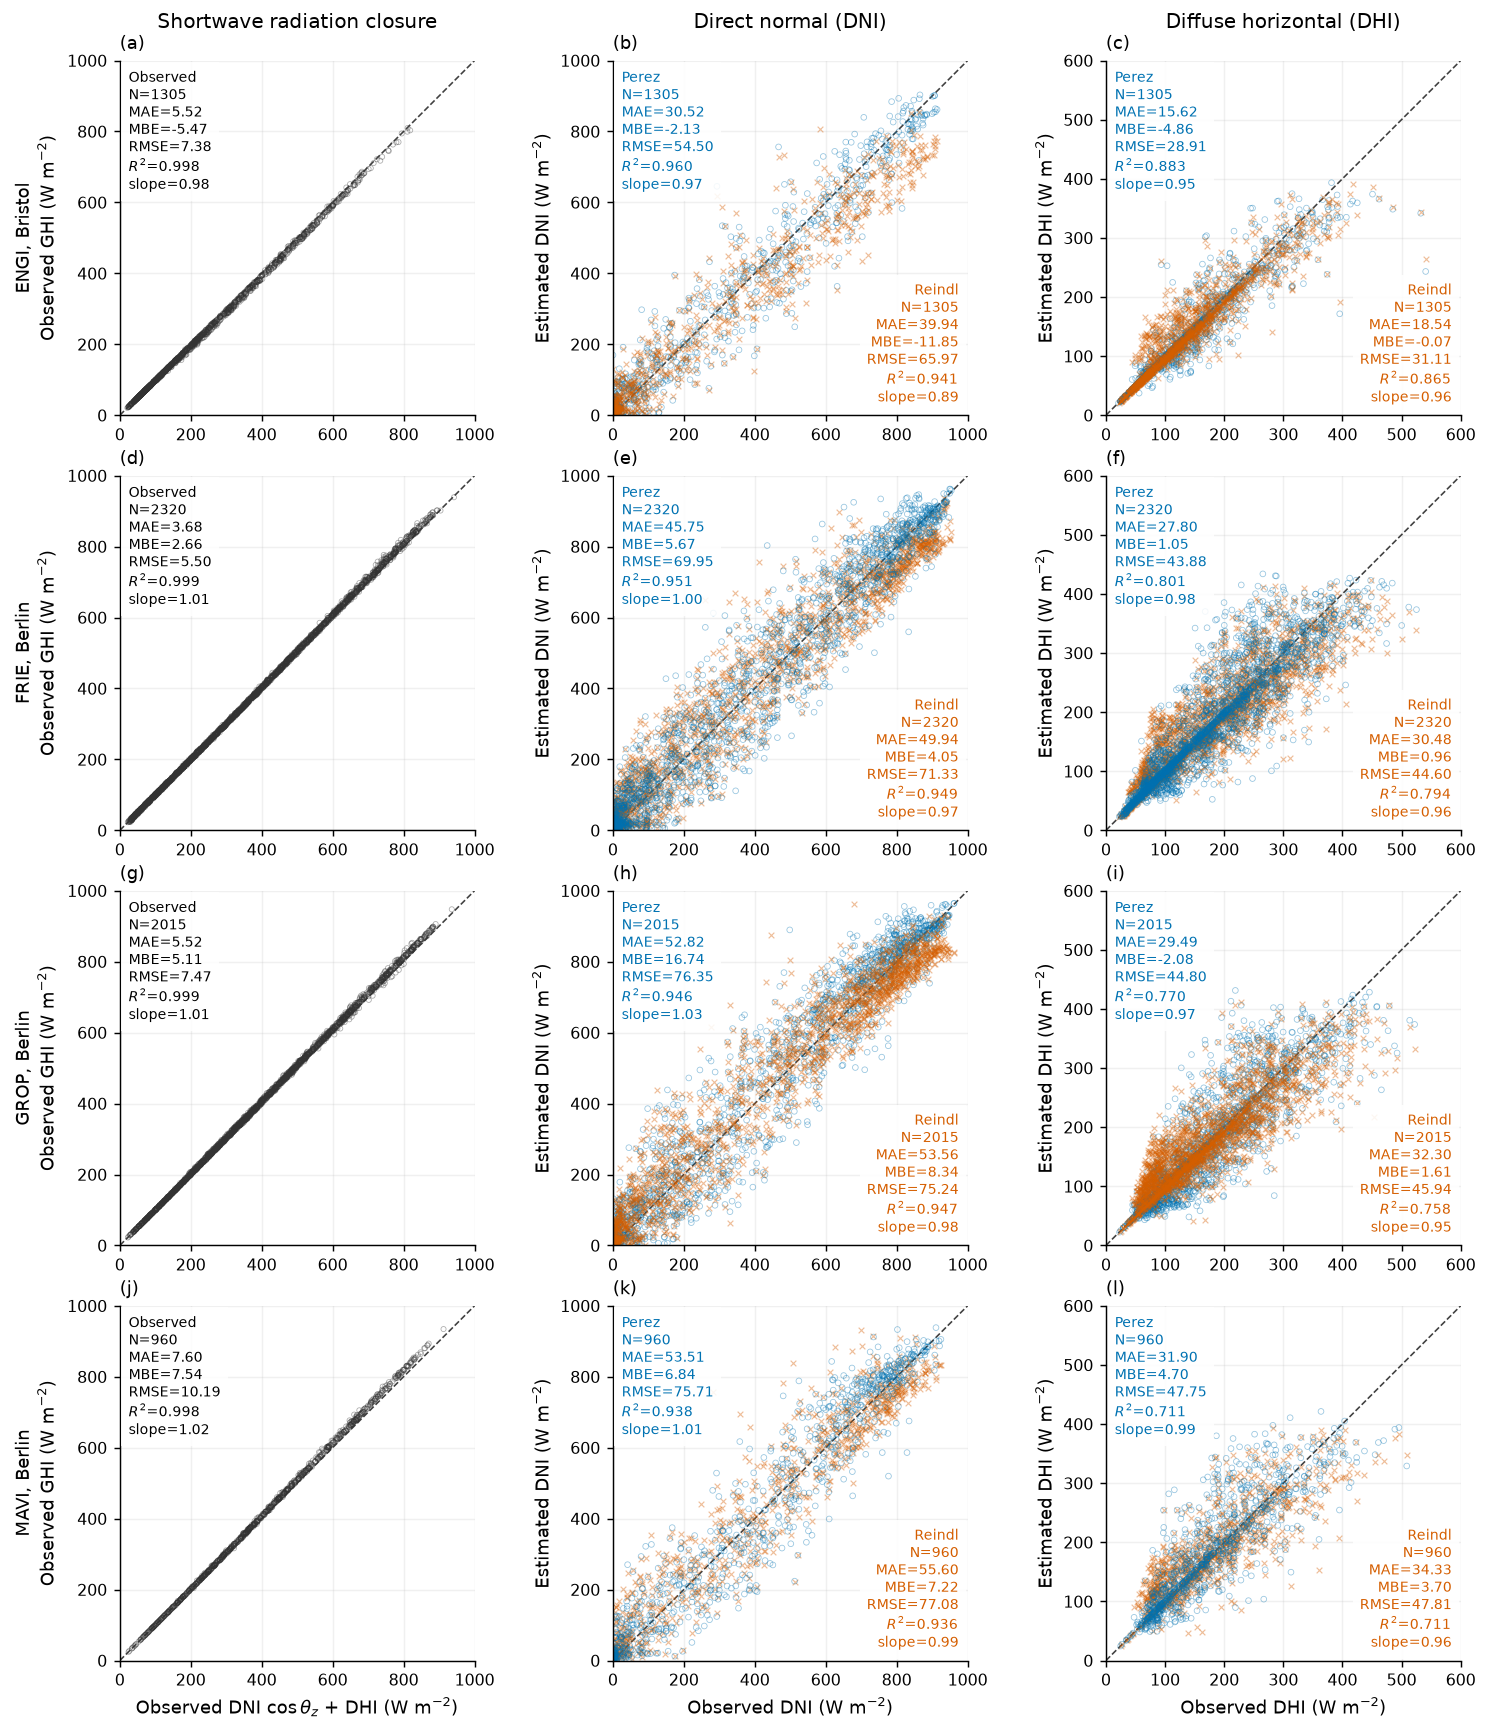

In [ ]:
components = ("Closure", "DNI", "DHI")
titles = ("Shortwave radiation closure", "Direct normal (DNI)", "Diffuse horizontal (DHI)")
limits = {}
for component in components:
    columns = ["SumSW_obs", "GHI"] if component == "Closure" else [component, f"Perez_{component}", f"Reindl_{component}"]
    values = np.concatenate([frame[columns].to_numpy().ravel() for frame in RESULTS.values()])
    limits[component] = (min(0., np.floor(values.min()/100)*100), max(100., np.ceil(values.max()/100)*100))
fig, axes = plt.subplots(4, 3, figsize=FIGSIZE)
fig.subplots_adjust(left=.10, right=.985, bottom=.05, top=.955, hspace=ROW_SPACING, wspace=.25)
for row, (site, frame) in enumerate(RESULTS.items()):
    for column, component in enumerate(components):
        ax = axes[row, column]
        low, high = limits[component]
        ax.plot([low, high], [low, high], color="0.25", ls="--", lw=.9, zorder=1)
        if component == "Closure":
            ax.scatter(frame.SumSW_obs, frame.GHI, s=8, facecolors="none", edgecolors="0.2",
                       alpha=.4, linewidths=.45, rasterized=True)
            ax.text(.025, .975, panel_text[(site, component, "Observed")], transform=ax.transAxes,
                va="top", fontsize=8, bbox=dict(facecolor="white", edgecolor="none", alpha=.85))
            ax.set_ylabel(f"{site}, {SITES[site]['city']}\n"
                          + r"Observed GHI (W m$^{-2}$)", fontweight="normal")
            if row == 3:
                ax.set_xlabel(r"Observed DNI $\cos\theta_z$ + DHI (W m$^{-2}$)")
        else:
            # Interleave drawing order by site, retaining identical style and full point sets.
            order = list(COLOURS) if row % 2 == 0 else list(reversed(COLOURS))
            for scheme in order:
                style = (dict(facecolors="none", edgecolors=COLOURS[scheme], linewidths=.45)
                         if scheme == "Perez" else dict(color=COLOURS[scheme], linewidths=.65))
                ax.scatter(frame[component], frame[f"{scheme}_{component}"], s=10,
                    marker=MARKERS[scheme], alpha=.4, rasterized=True, **style)
            for scheme in COLOURS:
                if scheme == "Perez":
                    position, horizontal, vertical = (.025, .975), "left", "top"
                else:
                    position, horizontal, vertical = (.975, .025), "right", "bottom"
                ax.text(*position, panel_text[(site, component, scheme)], transform=ax.transAxes,
                    ha=horizontal, va=vertical, fontsize=8, color=COLOURS[scheme],
                    bbox=dict(facecolor="white", edgecolor="none", alpha=.88))
            ax.set_ylabel(f"Estimated {component}" + r" (W m$^{-2}$)")
            if row == 3:
                ax.set_xlabel(f"Observed {component}" + r" (W m$^{-2}$)")
        ax.set(xlim=(low, high), ylim=(low, high), aspect="equal")
        ax.tick_params(labelsize=9)
        # Anchor above the left spine, clear of the y-axis tick labels.
        ax.annotate(f"({chr(97 + row*3 + column)})", xy=(0, 1),
            xycoords="axes fraction", xytext=(0, 4), textcoords="offset points",
            ha="left", va="bottom", fontsize=10, annotation_clip=False)
        if row == 0:
            ax.set_title(titles[column], fontsize=11, pad=18)

fig.savefig(FIGURE_DIR / 'figure_8.png', dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

## ERA5 radiation

Figures S6.1-S6.2 reuse the Bristol (ENGI) observations and splitting estimates
above for August 2024-March 2025. No predictions are recalculated after selecting
the common hours. Perez and Reindl use observed inputs, whereas ERA5 supplies its
own radiation; this is not an equal-input comparison of splitting schemes.

The ERA5 CSV is included in `ERA5_radiation/` and read using a relative path.
It comes from the [CDS ERA5 hourly time-series dataset](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-timeseries),
requested at **51.5 N, 2.5 W**, for **1 August 2024-2 April 2025**, with
`surface_solar_radiation_downwards` (`ssrd`) and
`total_sky_direct_solar_radiation_at_surface` (`fdir`). The original CSV contents
are unchanged. [Data documentation](ERA5_radiation/README.md) records the source,
units and CC BY 4.0 licence; `provenance.json` retains the request and checksums.
Run the notebook from this repository folder. No download or credentials are
needed for ERA5, but the observation comparisons still require authorised access
to the embargoed station radiation and meteorology.

Both radiation fields are one-hour accumulations in J m$^{-2}$, labelled at the
UTC interval end ([ECMWF documentation](https://confluence.ecmwf.int/spaces/CKB/pages/76414402/ERA5+data+documentation)).
Divide by 3600 once; do not difference successive hours or shift timestamps:

$$GHI_E=ssrd/3600,\quad BHI_E=fdir/3600,\quad DHI_E=(ssrd-fdir)/3600.$$

$$DNI_E\approx BHI_E/\cos\theta_{z,mid}.$$

The DNI conversion uses the station's apparent midpoint zenith from the existing
evaluation. It approximates hourly mean DNI, especially near sunrise and sunset.
Missing or nonphysical ERA5 pairs are excluded, not clipped. Every component
and method is scored on the same retained hours.

In [8]:
ERA5_FILE = Path('ERA5_radiation/ERA5_Bristol_radiation_hourly_20240801_20250402.csv')

era5_raw = pd.read_csv(ERA5_FILE,
    usecols=['valid_time', 'ssrd', 'fdir', 'latitude', 'longitude'])
if not (era5_raw.latitude.eq(51.5) & era5_raw.longitude.eq(-2.5)).all():
    raise ValueError('Expected the Bristol ERA5 grid point: 51.5 N, 2.5 W')
era5_raw.index = pd.DatetimeIndex(
    pd.to_datetime(era5_raw.pop('valid_time'), utc=True), name='time_end_utc')
if era5_raw.index.has_duplicates:
    raise ValueError('ERA5 input must contain one record per hourly timestamp')

# Reuse Figure 8's observed-input calculations and UTC interval-end labels.
bristol = RESULTS['ENGI'].loc['2024-08-01':'2025-03-31'].copy()
energy = era5_raw[['ssrd', 'fdir']].reindex(bristol.index)
valid_era5 = (np.isfinite(energy).all(axis=1) & energy.ssrd.gt(0)
             & energy.fdir.ge(0) & energy.fdir.le(energy.ssrd))
common = bristol.loc[valid_era5].copy()
energy = energy.loc[valid_era5]
common['ERA5_GHI'] = energy.ssrd / 3600.
common['ERA5_BHI'] = energy.fdir / 3600.
common['ERA5_DHI'] = (energy.ssrd - energy.fdir) / 3600.
common['ERA5_DNI'] = common.ERA5_BHI / np.cos(np.deg2rad(common.zenith_apparent))

display(pd.DataFrame([dict(observed_input_hours=len(bristol),
    excluded_era5_hours=int((~valid_era5).sum()), common_hours=len(common),
    first_end_utc=common.index.min(), last_end_utc=common.index.max())]))

era5_colours = {**COLOURS, 'ERA5': '#009E73'}
era5_markers = {**MARKERS, 'ERA5': '^'}
era5_metric_rows = [dict(component='GHI', scheme='ERA5',
                        **statistics(common.GHI, common.ERA5_GHI))]
for component in ('DNI', 'DHI'):
    for scheme in era5_colours:
        era5_metric_rows.append(dict(component=component, scheme=scheme,
            **statistics(common[component], common[f'{scheme}_{component}'])))
era5_metrics = pd.DataFrame(era5_metric_rows)
display(era5_metrics[['component', 'scheme', *PANEL_METRICS]].round(3))

era5_panel_text = {}
for _, scores in era5_metrics.iterrows():
    lines = []
    for name in PANEL_METRICS:
        label = r'$R^2$' if name == 'R2' else ('slope' if name == 'slope0' else name)
        value = (str(int(scores[name])) if name == 'N' else
                 f'{scores[name]:.3f}' if name == 'R2' else f'{scores[name]:.2f}')
        lines.append(f'{label}={value}')
    era5_panel_text[(scores['component'], scores['scheme'])] = '\n'.join(lines)

,observed_input_hours,excluded_era5_hours,common_hours,first_end_utc,last_end_utc
0,1305,0,1305,2024-08-02 08:00:00+00:00,2025-03-31 17:00:00+00:00


,component,scheme,N,MAE,MBE,RMSE,R2,slope0
0,GHI,ERA5,1305,69.883,7.728,98.072,0.700,0.944
1,DNI,Perez,1305,30.521,-2.127,54.499,0.960,0.967
2,DNI,Reindl,1305,39.945,-11.848,65.968,0.941,0.887
3,DNI,ERA5,1305,142.096,66.279,208.950,0.410,0.917
4,DHI,Perez,1305,15.620,-4.859,28.907,0.883,0.945
5,DHI,Reindl,1305,18.539,-0.068,31.115,0.865,0.960
6,DHI,ERA5,1305,48.728,-25.748,68.112,0.351,0.722


### Figure S6.1

ERA5 GHI against observed GHI, followed by the DNI and DHI comparisons. Colours
and markers identify the methods; dashed lines denote 1:1 agreement. Statistics
retain the definitions above, including slopes fitted through the origin.

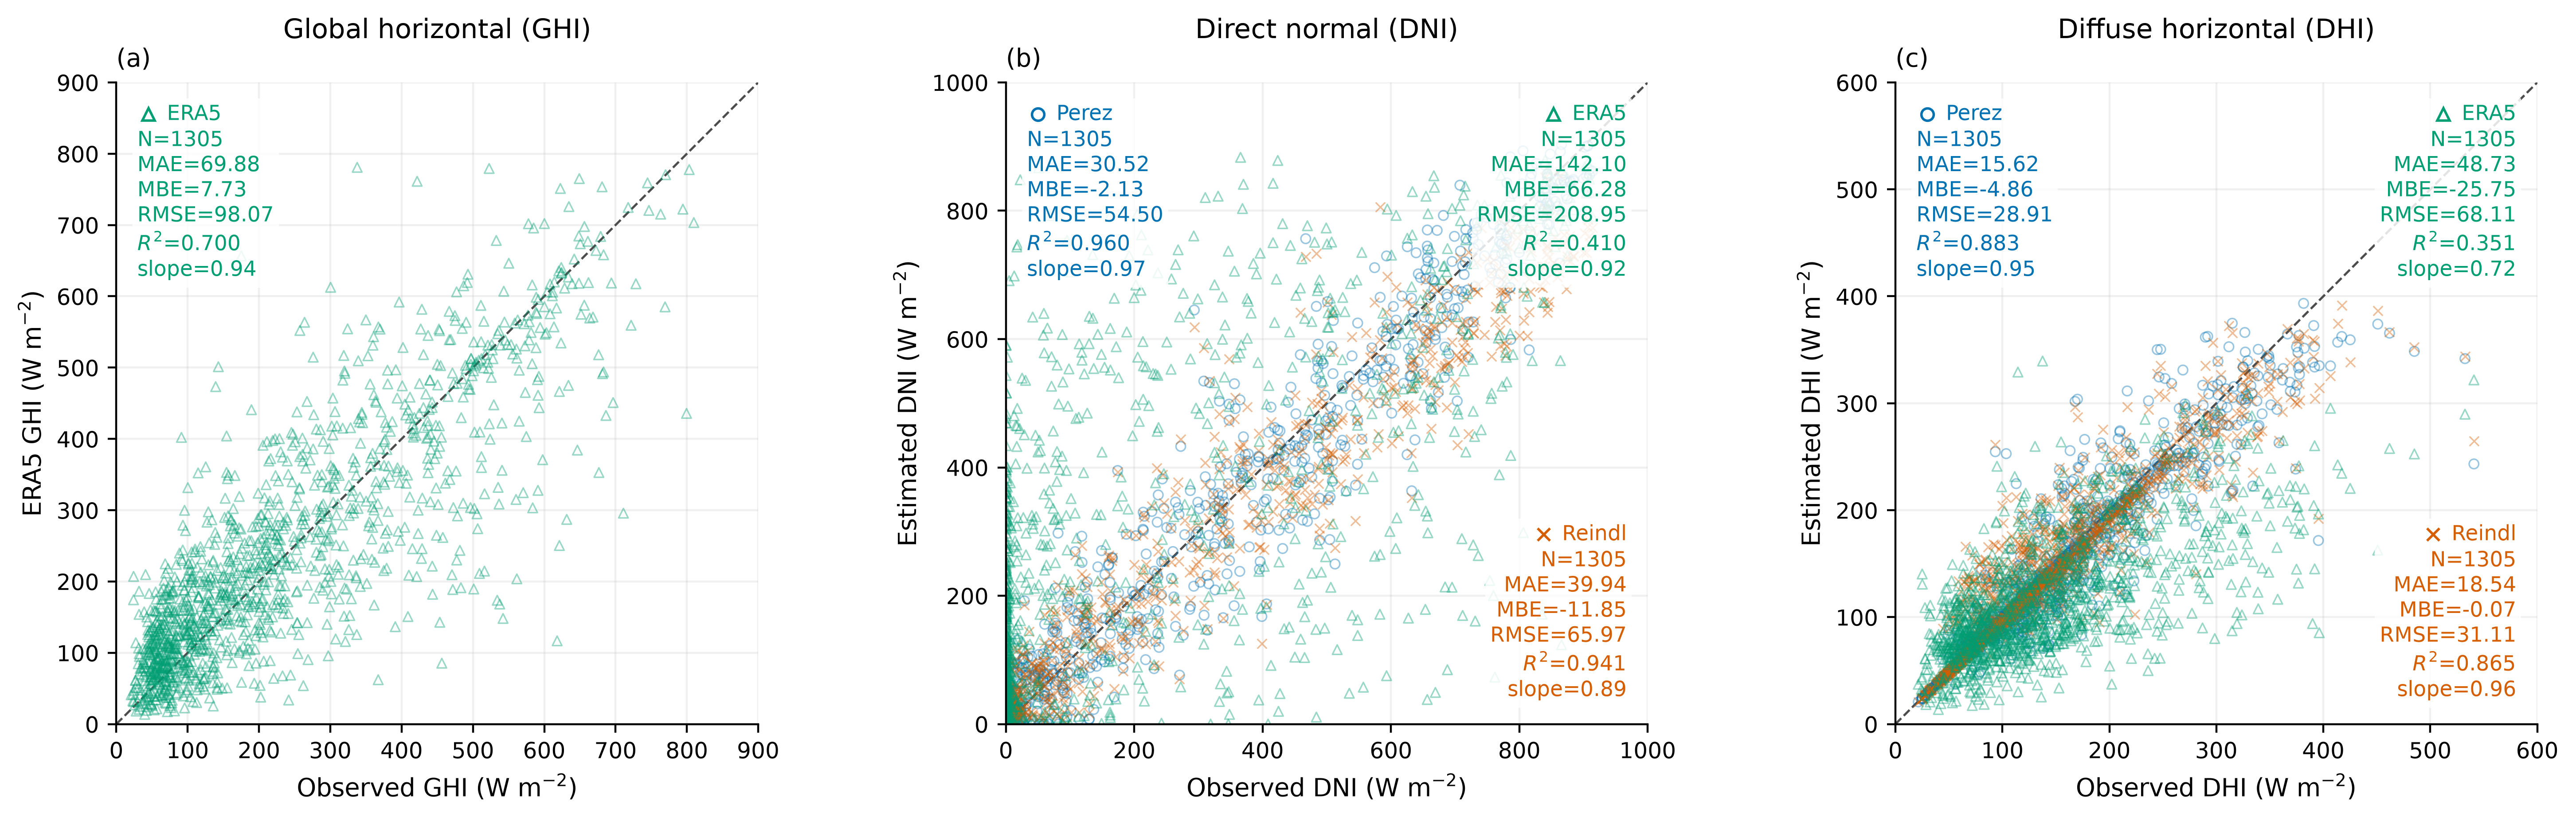

In [9]:
from matplotlib.lines import Line2D
from matplotlib.offsetbox import AnchoredOffsetbox, DrawingArea, HPacker, TextArea, VPacker

fig, axes = plt.subplots(1, 3, figsize=(15, 4.7))
fig.subplots_adjust(left=.055, right=.985, bottom=.13, top=.90, wspace=.28)
component_titles = ('Global horizontal (GHI)', 'Direct normal (DNI)', 'Diffuse horizontal (DHI)')
for column, (ax, component, title) in enumerate(zip(axes, ('GHI', 'DNI', 'DHI'), component_titles)):
    schemes = ('ERA5',) if component == 'GHI' else tuple(era5_colours)
    values = common[[component, *[f'{s}_{component}' for s in schemes]]].to_numpy()
    low = min(0., np.floor(values.min() / 100) * 100)
    high = max(100., np.ceil(values.max() / 100) * 100)
    ax.plot([low, high], [low, high], '--', color='0.3', lw=.9, zorder=1)
    for scheme in schemes:
        colour = era5_colours[scheme]
        style = (dict(color=colour) if scheme == 'Reindl'
                 else dict(facecolors='none', edgecolors=colour))
        ax.scatter(common[component], common[f'{scheme}_{component}'],
            marker=era5_markers[scheme], s=15, alpha=.4, linewidths=.6,
            rasterized=True, **style)

        if component == 'GHI' or scheme == 'Perez':
            position, location, alignment = (.025, .975), 'upper left', 'left'
        elif scheme == 'Reindl':
            position, location, alignment = (.975, .025), 'lower right', 'right'
        else:
            position, location, alignment = (.975, .975), 'upper right', 'right'
        symbol = DrawingArea(9, 9, 0, 0)
        symbol.add_artist(Line2D([4.5], [4.5], marker=era5_markers[scheme],
            markerfacecolor='none', markeredgecolor=colour, markersize=5,
            markeredgewidth=1., linestyle='none'))
        heading = HPacker(children=[symbol, TextArea(scheme,
            textprops=dict(color=colour, fontsize=8.5))], align='center', pad=0, sep=3)
        body = TextArea(era5_panel_text[(component, scheme)],
            textprops=dict(color=colour, fontsize=8.5, multialignment=alignment))
        annotation = AnchoredOffsetbox(loc=location,
            child=VPacker(children=[heading, body], align=alignment, pad=0, sep=1),
            bbox_to_anchor=position, bbox_transform=ax.transAxes,
            frameon=True, pad=.2, borderpad=0)
        annotation.patch.set(facecolor='white', edgecolor='none', alpha=.85)
        ax.add_artist(annotation)
    ylabel = 'ERA5 GHI' if component == 'GHI' else f'Estimated {component}'
    ax.set(xlim=(low, high), ylim=(low, high), aspect='equal',
           xlabel=f'Observed {component}' + r' (W m$^{-2}$)',
           ylabel=ylabel + r' (W m$^{-2}$)')
    ax.set_title(title, pad=18, fontsize=11)
    ax.annotate(f'({chr(97 + column)})', xy=(0, 1), xycoords='axes fraction',
        xytext=(0, 4), textcoords='offset points', ha='left', va='bottom',
        fontsize=10, annotation_clip=False)
fig.savefig(FIGURE_DIR / 'figure_S6_1.png', dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

### Figure S6.2

Compare ratios of hourly mean DHI to GHI, not hourly means of minute-level ratios.
Observations, Perez and Reindl use observed GHI as the denominator; ERA5 uses its
own GHI. Ratios are not clipped to one.

Group hours using observed $k_t=GHI/(I_{0,n}\cos\theta_z)$ at the interval
midpoint: low ($k_t\leq0.35$), intermediate ($0.35<k_t\leq0.65$) and high
($k_t>0.65$) clearness. These are clearness proxies, not measured cloud classes.
The grouping uses true zenith and the standard Spencer correction in pvlib
(solar constant 1366.1 W m$^{-2}$), independently of the Reindl predictor.
Every retained hour belongs to exactly one group; predictions are not refitted.

Fraction errors are dimensionless (0.01 is one percentage point). Predictive
$R^2$ may be negative, especially when observed fractions vary little within
a group. This comparison does not establish whether Perez driven by ERA5 GHI
would outperform ERA5's own radiation components.

In [10]:
CLOUDY_KT_MAX, CLEAR_KT_MIN = .35, .65
SKY_SOLAR_CONSTANT = 1366.1

fractions = pd.DataFrame(index=common.index)
fractions['Observed'] = common.DHI / common.GHI
for scheme in era5_colours:
    denominator = common.ERA5_GHI if scheme == 'ERA5' else common.GHI
    fractions[scheme] = common[f'{scheme}_DHI'] / denominator
midpoints = pd.DatetimeIndex(common.time_midpoint_utc)
extra_normal = pvlib.irradiance.get_extra_radiation(
    midpoints, solar_constant=SKY_SOLAR_CONSTANT, method='spencer').to_numpy()
extra_horizontal = extra_normal * np.cos(np.deg2rad(common.zenith_true))
fractions['kt_observed'] = common.GHI / extra_horizontal
fractions['sky_group'] = np.select(
    [fractions.kt_observed.le(CLOUDY_KT_MAX), fractions.kt_observed.le(CLEAR_KT_MIN)],
    ['cloudy', 'intermediate'], default='clear')

sky_metric_rows = []
for group in ('cloudy', 'intermediate', 'clear'):
    subset = fractions.loc[fractions.sky_group.eq(group)]
    for scheme in era5_colours:
        sky_metric_rows.append(dict(sky_group=group, scheme=scheme,
                                    **statistics(subset.Observed, subset[scheme])))
sky_metrics = pd.DataFrame(sky_metric_rows)
display(sky_metrics[['sky_group', 'scheme', *PANEL_METRICS]].round(4))

sky_panel_text = {}
for _, scores in sky_metrics.iterrows():
    lines = [scores['scheme']]
    for name in PANEL_METRICS:
        label = r'$R^2$' if name == 'R2' else ('slope' if name == 'slope0' else name)
        value = (str(int(scores[name])) if name == 'N' else
                 f'{scores[name]:.2f}' if name == 'slope0' else f'{scores[name]:.3f}')
        lines.append(f'{label}={value}')
    sky_panel_text[(scores['sky_group'], scores['scheme'])] = '\n'.join(lines)

,sky_group,scheme,N,MAE,MBE,RMSE,R2,slope0
0,cloudy,Perez,715,0.0311,-0.0192,0.0464,-0.0938,0.9795
1,cloudy,Reindl,715,0.0434,-0.0328,0.0522,-0.3877,0.9660
2,cloudy,ERA5,715,0.2057,-0.2040,0.2756,-37.6211,0.7983
3,intermediate,Perez,429,0.0937,-0.0248,0.1177,0.7116,0.9366
4,intermediate,Reindl,429,0.0958,-0.0121,0.1187,0.7068,0.9436
5,intermediate,ERA5,429,0.2293,-0.1456,0.2880,-0.7258,0.7363
6,clear,Perez,161,0.0534,-0.0257,0.0784,0.3998,0.8521
7,clear,Reindl,161,0.0863,0.0443,0.1031,-0.0399,1.0376
8,clear,ERA5,161,0.1164,0.0550,0.1726,-1.9135,1.1581


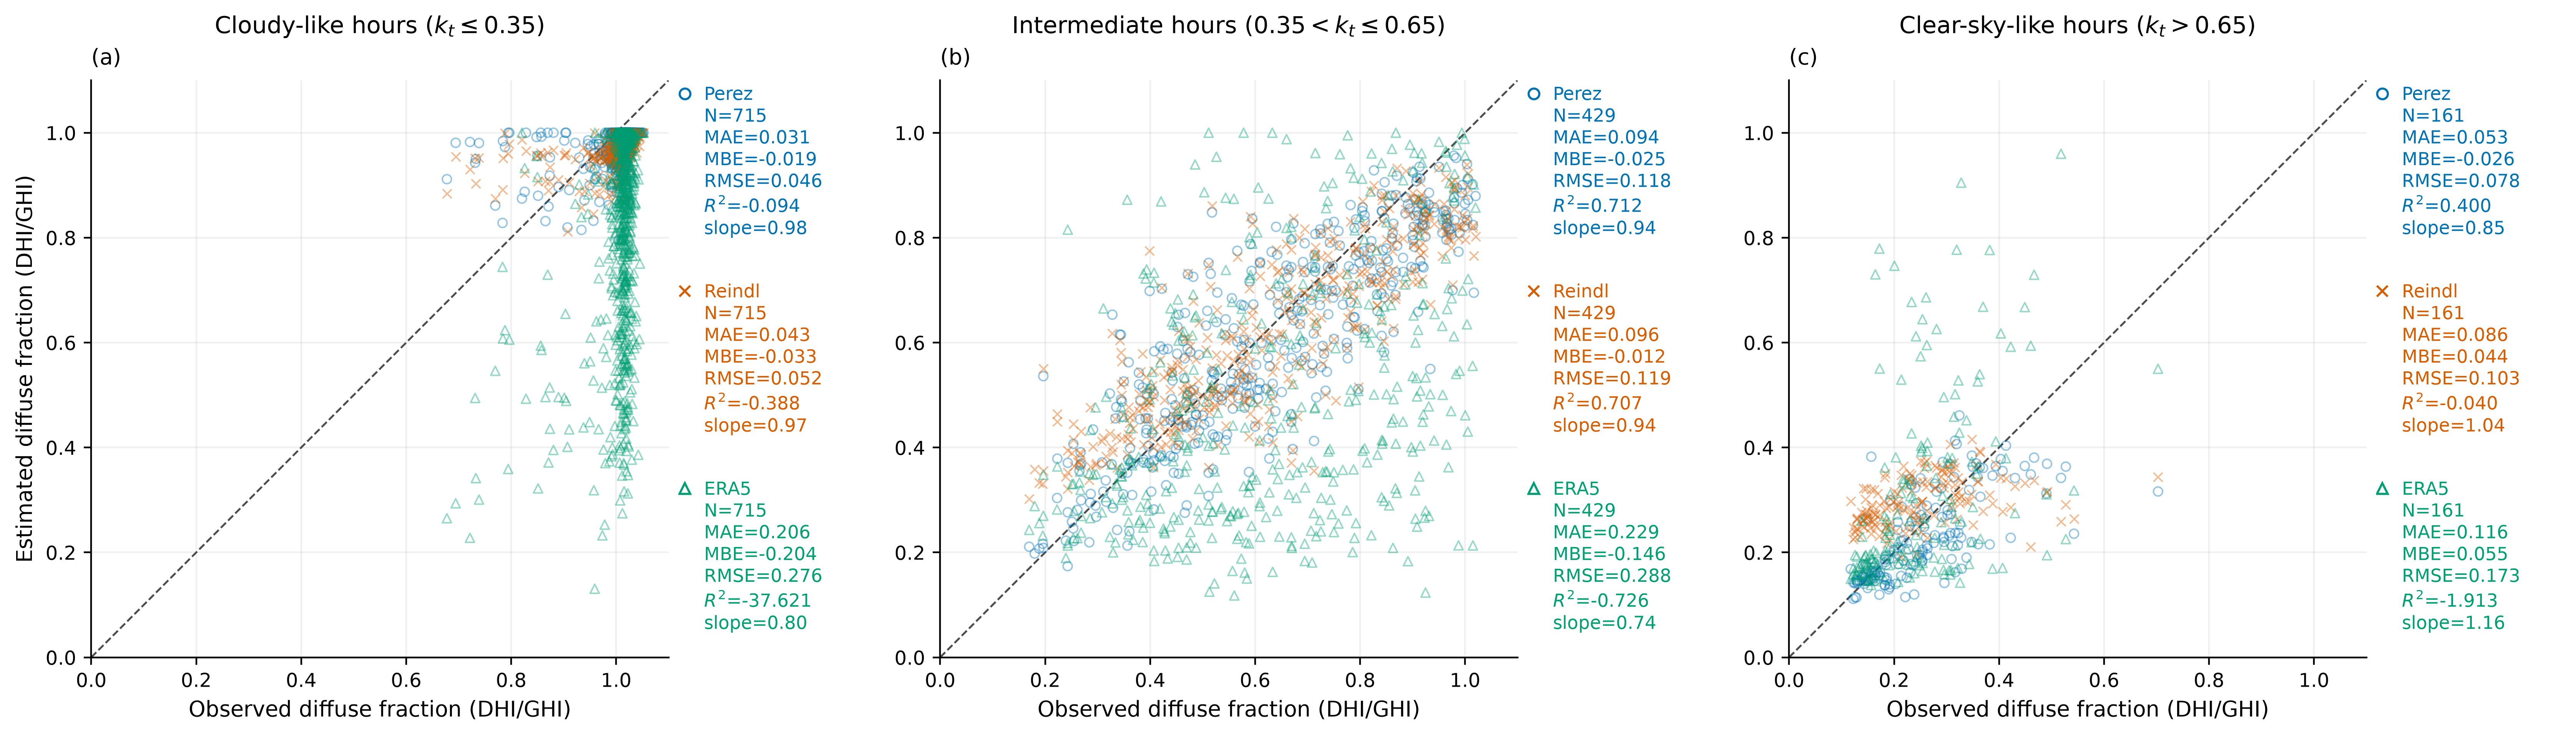

In [11]:
values = fractions[['Observed', *era5_colours]].to_numpy()
low = min(0., np.floor(values.min() * 10) / 10)
high = max(1.1, np.ceil(values.max() * 10) / 10)
sky_titles = [f'Cloudy-like hours ($k_t \\leq {CLOUDY_KT_MAX:g}$)',
              f'Intermediate hours (${CLOUDY_KT_MAX:g} < k_t \\leq {CLEAR_KT_MIN:g}$)',
              f'Clear-sky-like hours ($k_t > {CLEAR_KT_MIN:g}$)']
fig = plt.figure(figsize=(17, 5.4))
grid = fig.add_gridspec(1, 3, left=.05, right=.995, bottom=.14, top=.84, wspace=.10)
for column, (group, title) in enumerate(zip(('cloudy', 'intermediate', 'clear'), sky_titles)):
    pair = grid[0, column].subgridspec(1, 2, width_ratios=[1, .32], wspace=.025)
    ax = fig.add_subplot(pair[0, 0])
    text_ax = fig.add_subplot(pair[0, 1])
    text_ax.set_axis_off()
    subset = fractions.loc[fractions.sky_group.eq(group)]
    ax.plot([low, high], [low, high], '--', color='0.3', lw=.9, zorder=1)
    for scheme, text_y in zip(era5_colours, [.99, .65, .31]):
        colour = era5_colours[scheme]
        style = (dict(color=colour) if scheme == 'Reindl'
                 else dict(facecolors='none', edgecolors=colour))
        ax.scatter(subset.Observed, subset[scheme], marker=era5_markers[scheme],
            s=18, alpha=.4, linewidths=.7, rasterized=True, **style)
        text_ax.plot([.035], [text_y - .016], marker=era5_markers[scheme],
            color=colour, markerfacecolor='none', markersize=5,
            markeredgewidth=1., linestyle='none', transform=text_ax.transAxes)
        text_ax.text(.14, text_y, sky_panel_text[(group, scheme)], color=colour,
            fontsize=8.5, ha='left', va='top', transform=text_ax.transAxes)
    ax.set(xlim=(low, high), ylim=(low, high), aspect='equal',
           xlabel='Observed diffuse fraction (DHI/GHI)')
    if column == 0:
        ax.set_ylabel('Estimated diffuse fraction (DHI/GHI)')
    ax.set_title(title, pad=22, fontsize=11)
    ax.annotate(f'({chr(97 + column)})', xy=(0, 1), xycoords='axes fraction',
        xytext=(0, 5), textcoords='offset points', va='bottom',
        fontsize=10, annotation_clip=False)
fig.savefig(FIGURE_DIR / 'figure_S6_2.png', dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()